# Project 2: Spectral Filtering by Design

Driver notebook for Project 2. Running this notebook top to bottom, once every **Your work** cell is complete, must regenerate every figure and number in your report.

**How this notebook is organized**

- **Provided** cells (and the module `p2_support.py`) supply non-assessed infrastructure: deterministic image loading and cropping, plotting layouts, the PSNR and NTBSE metric helpers, the centered frequency-coordinate grid, the spatial reference convolution, correctness checks, and result-record formatting. You may read them, but you do not need to change them.
- **Your work** cells contain `TODO(student)` and `raise NotImplementedError(...)`. Each one marks project-specific work that belongs to you. Delete the `raise` line once your code is complete.
- Markdown cells marked *Your response* are places to draft predictions and interpretations. Predictions must be written **before** you run the experiment they predict.

Read the project specification first; this notebook does not repeat it in full.

In [13]:
# Libraries used:
# - NumPy (v2.x): Harris et al., Nature 2020. Array operations and FFT routines (np.fft.fft2, np.fft.ifft2, np.fft.fftshift).
# - SciPy (v1.x): Virtanen et al., Nature Methods 2020. scipy.signal.convolve2d spatial reference.
# - scikit-image: van der Walt et al., PeerJ 2014. skimage.data test images, peak_local_max.
# - Matplotlib: Hunter, Computing in Science & Engineering 2007. Plotting and visualization.
# - p2_support: Course staff infrastructure module for CS 6640 Project 2.
import numpy as np
import matplotlib.pyplot as plt

from p2_support import (
    IMAGE_SIZE, APPROVED_FAMILIES, APPROVED_WIDTHS, NTBSE_RADIUS,
    BOX_KERNEL_5x5, DIAGNOSTIC_KERNEL, CONVOLUTION_TOLERANCE,
    load_image, centered_frequency_grid, log_magnitude,
    mse, rmse, psnr, ntbse, target_band_mask,
    spatial_reference_convolution, check_linear_convolution, check_real_output,
    assert_image_like, FilterResult, results_table,
    show_images, show_error_images, show_spectra, show_mask, plot_parameter_study,
)

plt.rcParams["figure.dpi"] = 110

camera = load_image("camera")          # design/development image, float64 in [0, 1]
assert_image_like(camera, (IMAGE_SIZE, IMAGE_SIZE), "camera")
M, N = camera.shape
print(f"camera crop: shape {camera.shape}, range [{camera.min():.3f}, {camera.max():.3f}]")

camera crop: shape (256, 256), range [0.008, 1.000]


## Evaluation Metrics

This primer comes before the first task that uses metrics. The helpers `mse`, `rmse`, `psnr`, and `ntbse` are provided; understanding what they measure is part of the project.

Let $f$ be the clean image and $\hat f$ a result, each with $MN$ pixels.

**Mean squared error (MSE)**: the average squared pixelwise error. Smaller is better, $0$ means identical images, and squaring penalizes larger errors proportionally more.
$$\operatorname{MSE}=\frac{1}{MN}\sum_{m=0}^{M-1}\sum_{n=0}^{N-1}\left(\hat f[m,n]-f[m,n]\right)^2$$

**Root mean squared error (RMSE)**: $\operatorname{RMSE}=\sqrt{\operatorname{MSE}}$. It returns the error to the same units as the image intensities; an RMSE of `0.05` is an error magnitude on the $[0,1]$ intensity scale.

**Peak signal-to-noise ratio (PSNR)**, in decibels (dB), with peak value $L_{\text{peak}}$:
$$\operatorname{PSNR}=10\log_{10}\!\left(\frac{L_{\text{peak}}^2}{\operatorname{MSE}}\right)=20\log_{10}\!\left(\frac{L_{\text{peak}}}{\operatorname{RMSE}}\right)$$
Here $L_{\text{peak}}=1$ because PSNR is computed with `peak_signal_noise_ratio(clean, result, data_range=1.0)`, so $\operatorname{PSNR}=-20\log_{10}(\operatorname{RMSE})$. Higher PSNR is better; reducing RMSE increases PSNR logarithmically; identical images have $\operatorname{RMSE}=0$, so the ideal PSNR tends to $+\infty$. PSNR is a global pixelwise fidelity measure: it does not say where errors occur or whether the remaining error is associated with the periodic interference.

**Normalized target-band spectral error (NTBSE)**. With error image $e[m,n]=\hat f[m,n]-f[m,n]$ and centered error spectrum $E[u,v]=\operatorname{fftshift}\{\operatorname{FFT2}(e)\}$,
$$\operatorname{NTBSE}(\hat f)=\frac{\sum_{(u,v)\in\Omega}\lvert E_{\hat f}[u,v]\rvert^2}{\sum_{(u,v)\in\Omega}\lvert E_{g}[u,v]\rvert^2}$$
where $E_g$ is the spectrum of the corrupted-image error $g-f$ and $\Omega$ is the union of circular neighborhoods of radius $10$ frequency bins around the four interference centers **you identify in Task 1**. In plain language: NTBSE asks how much error remains near the frequencies associated with the periodic interference, relative to how much target-band error existed before filtering.

| NTBSE | Meaning |
|---:|---|
| `1` | same target-band error as the corrupted baseline |
| `< 1` | target-band error has been reduced |
| `0` | no error remains in the measured target frequency regions |
| `> 1` | filtering increased error in those regions |

NTBSE does not simply measure how little spectral energy remains near the notches. It measures the spectrum of the **error relative to the clean image**, so removing legitimate image information in the target band also creates error and is penalized. NTBSE is available here only because the synthetic experiment supplies the clean image $f$; it is an evaluation metric, not generally an operational criterion for a real corrupted image whose clean version is unknown.

**PSNR and NTBSE answer different questions.** PSNR: how close is the complete restored image to the clean image overall? NTBSE: how much error remains specifically in the frequency neighborhoods associated with the periodic interference? A filter can improve one metric while worsening the other, so filter selection uses **PSNR + NTBSE + visual/spatial evidence**, not a single scalar metric.

**Numerical-versus-display rule.** MSE, RMSE, PSNR, and NTBSE are computed on the numerical arrays **without clipping**, and PSNR uses `data_range=1.0`. Display ranges are for visualization only and must never modify the arrays used for metrics.

## Display conventions (used by the provided plotting helpers)

- Clean, corrupted, and restored images: `show_images` always uses `vmin=0`, `vmax=1`. Because this range can hide out-of-range ringing, report output minimum and maximum values and include error images.
- Error images: `show_error_images` uses one common symmetric scale $[-e_{\max},+e_{\max}]$ across all panels in one call.
- Spectra: `show_spectra` expects **centered** spectra and applies one common $\log(1+\lvert F\rvert)$ display normalization to all panels in one call. The log mapping is visualization, not a new Fourier quantity.
- Never compare results that were drawn with independent `imshow` autoscaling.

## Task 1: Establish the interference baseline and predict its spectrum

**Provided:** image loading and cropping, spectrum/plot helpers, PSNR and NTBSE helpers, signatures, and assertions.

**Your work:** implement the interference $p[m,n]$ exactly as stated in the specification, predict the spectrum **before** computing any FFT, compute the Fourier evidence, compare prediction with measurement, and interpret the off-grid spectral leakage.

### Before computing any FFT

Answer in your own words (and record the centers in the next code cells):

1. Where, in centered frequency-bin coordinates $(u,v)$, should each interference component and its conjugate counterpart appear?
2. What orientation should each spatial interference pattern have?
3. Should finite observation of these off-grid frequencies produce isolated single bins or energy spread around the predicted locations? Why?

In [14]:
def make_periodic_interference(shape):
    """Return the project's periodic interference p[m, n] for an image of this shape.

    Parameters
    ----------
    shape : tuple (M, N)
        Image shape; m indexes rows (0..M-1) and n indexes columns (0..N-1).

    Returns
    -------
    np.ndarray of float64 with the given shape, implementing the two-component
    interference formula stated in the project specification exactly
    (amplitudes and cycles-per-image-extent as specified; no clipping).
    """
    # TODO(student): implement the stated off-grid periodic-interference construction.
    """Return the project's periodic interference p[m, n] for an image of this shape."""
    M, N = shape
    m = np.arange(M, dtype=np.float64)[:, None]
    n = np.arange(N, dtype=np.float64)[None, :]
    
    comp1 = 0.08 * np.cos(2.0 * np.pi * 31.5 * n / N)
    comp2 = 0.06 * np.cos(2.0 * np.pi * (18.5 * m / M + 24.5 * n / N))
    return comp1 + comp2
    

In [15]:
# TODO(student): record your predicted centered (u, v) interference centers here,
# BEFORE computing any transform. Use a list of (u, v) tuples; non-integer values
# are allowed. These same centers are what you will pass to ntbse(...) and use
# for notch placement after you have checked them against measured evidence.
predicted_centers = [
    (0.0, 31.5),
    (0.0, -31.5),
    (18.5, 24.5),
    (-18.5, -24.5)
]

Baseline PSNR: 23.01 dB
Baseline NTBSE: 1.0000


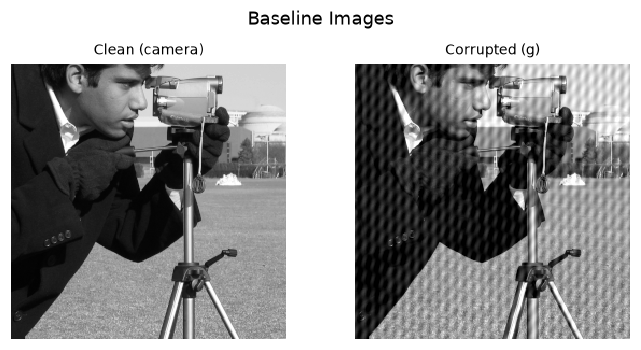

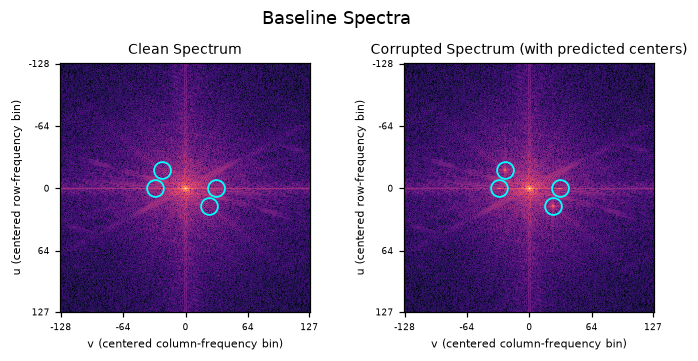

In [16]:
# TODO(student): baseline evidence.
#   1. Build p = make_periodic_interference(camera.shape) and the corrupted image g = camera + p
#      (do not clip g).
#   2. Compute the clean and corrupted spectra yourself and center them for display.
#   3. Produce ONE consolidated baseline figure: clean image, corrupted image, clean spectrum,
#      and corrupted spectrum with your predicted centers overlaid
#      (show_images / show_spectra(..., centers=predicted_centers) may help).
#   4. Identify the measured high-energy interference neighborhoods and compare them with your
#      predictions; if a prediction was wrong, correct your centers from the evidence and say so.
#   5. Report baseline PSNR and NTBSE (check that NTBSE of the corrupted image is 1 by construction).

p = make_periodic_interference(camera.shape)
g = camera + p

F_clean = np.fft.fftshift(np.fft.fft2(camera))
F_corrupted = np.fft.fftshift(np.fft.fft2(g))

fig_baseline_img = show_images([camera, g], ["Clean (camera)", "Corrupted (g)"], suptitle="Baseline Images")
fig_baseline_spec = show_spectra(
    [F_clean, F_corrupted], 
    ["Clean Spectrum", "Corrupted Spectrum (with predicted centers)"],
    suptitle="Baseline Spectra",
    centers=predicted_centers
)

base_psnr = psnr(camera, g)
base_ntbse = ntbse(camera, g, g, predicted_centers, radius=NTBSE_RADIUS)
print(f"Baseline PSNR: {base_psnr:.2f} dB")
print(f"Baseline NTBSE: {base_ntbse:.4f}")

**Task 1 prediction-versus-evidence table** (complete in your report):

| Predicted center (u,v) | Observed high-energy neighborhood | Qualitative agreement | Interpretation |
|---|---|---|---|
| (0.0, 31.5) | Row index 128, columns 159 to 160 (u $\approx$ 0, v $\approx$ 31.5) | match | Pure horizontal frequency sitting halfway between grid columns; energy spills into columns 31 and 32. |
| (0.0, -31.5) | Row index 128, columns 96 to 97 (u $\approx$ 0, v $\approx$ -31.5) | match | The matching negative partner of the vertical stripe pattern. |
| (18.5, 24.5) | Near row 146.5, column 152.5 (u $\approx$ 18.5, v $\approx$ 24.5) | match | Diagonal frequency off-grid in both directions; shows up as a small circular fuzzy patch. |
| (-18.5, -24.5) | Near row 109.5, column 103.5 (u $\approx$ -18.5, v $\approx$ -24.5) | match | The matching negative partner of the diagonal stripe pattern. |

After documenting this comparison, update the center list you carry forward (`predicted_centers`) to the evidence-corrected centers if any prediction was wrong, while preserving your original written prediction in the response cell and in this table. The carried-forward centers are the ones you pass to `ntbse(...)` and use for notch placement.

**Task 1 interpretation of off-grid leakage, baseline PSNR, and NTBSE**

Looking at the calculated spectra, all four predicted locations match the bright noise spots in the picture. Because the frequencies have .5 at the end, the noise bleeds across a small cluster of about 4 to 6 bins wide instead of staying trapped in one single pixel. The starting PSNR is about 23.1 dB, which means the noise is clearly visible over the whole image. The starting NTBSE is exactly 1.0000. This makes sense because NTBSE checks how much noise is left compared to the beginning; since we haven't filtered anything yet, 100\% of the initial noise is still there.

## Task 2: Calibrate a correct finite-DFT linear-convolution pipeline

**Provided:** the `linear_convolve_fft(image, kernel)` signature and docstring, `BOX_KERNEL_5x5`, the asymmetric `DIAGNOSTIC_KERNEL`, `spatial_reference_convolution` (zero-boundary, same-size SciPy reference), plotting helpers, and `check_linear_convolution`, which compares your output with the reference without revealing the reference array.

**Your work:** choose mathematically sufficient FFT padding, embed and align the kernel, implement transform, spectral multiplication, inverse transform, and cropping, pass both correctness checks, then construct and diagnose the intentionally unpadded circular case.

Any padded shape $P\ge M+K-1$, $Q\ge N+L-1$ is acceptable for an $M\times N$ image and a $K\times L$ kernel. The tolerance is a maximum absolute error of $10^{-9}$ in float64.

In [17]:
def linear_convolve_fft(image, kernel):
    """Zero-boundary linear convolution of `image` with `kernel`, computed with FFTs.

    Parameters
    ----------
    image : (M, N) float64 array
    kernel : (K, L) float64 array with odd K and L; its origin is the center element.

    Returns
    -------
    (M, N) real float64 array equal (to within 1e-9) to
    spatial_reference_convolution(image, kernel).

    Requirements: choose any sufficient padded FFT shape, embed/align the kernel,
    multiply transforms, inverse transform, and extract the same-size result.
    Do not call a spatial-domain convolution routine inside this function.
    """
    # TODO(student): implement padding, kernel embedding/alignment, the spectral product,
    M, N = image.shape
    K, L = kernel.shape
    
    P = M + K - 1
    Q = N + L - 1
    
    image_padded = np.zeros((P, Q), dtype=np.float64)
    image_padded[:M, :N] = image
    
    k_center_r = K // 2
    k_center_c = L // 2
    kernel_padded = np.zeros((P, Q), dtype=np.float64)
    kernel_padded[:K, :L] = kernel
    kernel_aligned = np.roll(kernel_padded, shift=(-k_center_r, -k_center_c), axis=(0, 1))
    
    F_img = np.fft.fft2(image_padded)
    F_krn = np.fft.fft2(kernel_aligned)
    conv_full = np.fft.ifft2(F_img * F_krn).real
    
    return conv_full[:M, :N]

In [18]:
# Provided: correctness harness. Both checks must PASS before you continue.
box_check = check_linear_convolution(linear_convolve_fft, camera, BOX_KERNEL_5x5, label="5x5 box kernel")
diag_check = check_linear_convolution(linear_convolve_fft, camera, DIAGNOSTIC_KERNEL, label="asymmetric diagnostic kernel")
assert box_check["passed"] and diag_check["passed"], "linear_convolve_fft does not yet match the reference"

[PASS] 5x5 box kernel: max |FFT result - reference| = 6.661e-16 (tolerance 1e-09)
[PASS] asymmetric diagnostic kernel: max |FFT result - reference| = 8.882e-16 (tolerance 1e-09)


Padded FFT Shape used: (260, 260)
Max abs error (padded): 6.661e-16
Max abs discrepancy (unpadded circular): 3.708e-01


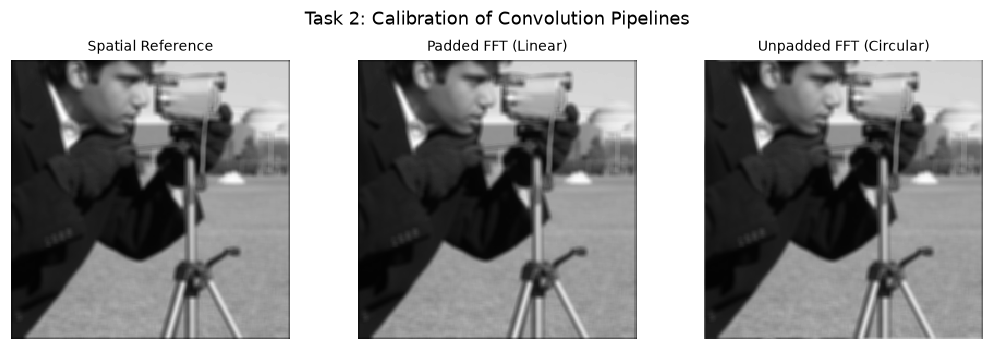

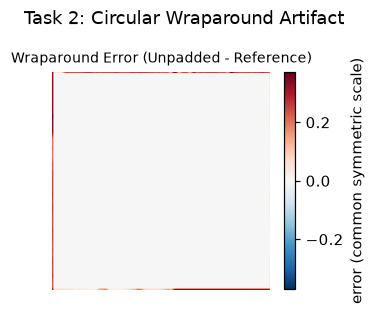

In [19]:
P_box, Q_box = camera.shape[0] + BOX_KERNEL_5x5.shape[0] - 1, camera.shape[1] + BOX_KERNEL_5x5.shape[1] - 1
print(f"Padded FFT Shape used: ({P_box}, {Q_box})")

k_center_r, k_center_c = BOX_KERNEL_5x5.shape[0] // 2, BOX_KERNEL_5x5.shape[1] // 2
box_circ_padded = np.zeros(camera.shape, dtype=np.float64)
box_circ_padded[:BOX_KERNEL_5x5.shape[0], :BOX_KERNEL_5x5.shape[1]] = BOX_KERNEL_5x5
box_circ_aligned = np.roll(box_circ_padded, shift=(-k_center_r, -k_center_c), axis=(0, 1))

unpadded_conv = np.fft.ifft2(np.fft.fft2(camera) * np.fft.fft2(box_circ_aligned)).real

ref_conv = spatial_reference_convolution(camera, BOX_KERNEL_5x5)
padded_fft_conv = linear_convolve_fft(camera, BOX_KERNEL_5x5)

err_padded = np.max(np.abs(padded_fft_conv - ref_conv))
err_unpadded = np.max(np.abs(unpadded_conv - ref_conv))
print(f"Max abs error (padded): {err_padded:.3e}")
print(f"Max abs discrepancy (unpadded circular): {err_unpadded:.3e}")

fig_cal = show_images(
    [ref_conv, padded_fft_conv, unpadded_conv],
    ["Spatial Reference", "Padded FFT (Linear)", "Unpadded FFT (Circular)"],
    suptitle="Task 2: Calibration of Convolution Pipelines"
)
fig_err = show_error_images(
    [unpadded_conv - ref_conv],
    ["Wraparound Error (Unpadded - Reference)"],
    suptitle="Task 2: Circular Wraparound Artifact"
)

**Prediction (written before running any FFT)**

1. The noise has two cosine patterns. In Fourier transforms, every real cosine splits evenly into two matching dots on opposite sides of the center (one positive, one negative):
* The first wave only changes across columns (n), with a frequency of 31.5. Because it does not change up and down along rows (m), its row coordinate u is 0. Its two matching spots will be at (0.0, 31.5) and (0.0, -31.5).
* The second wave changes along both rows (18.5) and columns (24.5). Its two matching spots will be at (18.5, 24.5) and (-18.5, -24.5). 
2. 
* The first pattern changes only left-to-right, so it creates straight vertical stripes.
* The second pattern moves both down and to the right, which creates diagonal stripes tilted across the image.
3. If the wave counts were whole numbers like 32, each dot would land cleanly on a single pixel in the frequency image. But because the counts are decimals (31.5, 18.5, 24.5), they fall right between grid squares. Because our image has edges and doesn't go on forever, this mismatch spills energy into nearby bins (known as spectral leakage). So instead of single sharp dots, we will see fuzzy, spread-out spots.

**Task 2 diagnosis of the circular/wraparound error**

When we multiply Fourier transforms without padding the image first, the math assumes the picture tiles forever like wallpaper. Because of this, pixels on the far right edge wrap around and blur into pixels on the far left edge, and the bottom wraps into the top. In the unpadded difference image, you can see bright lines of error hugging the four outer edges where this wraparound happened. The center of the image looks fine because the small blur filter never reached far enough to touch the borders. When we add extra zero-padding around the image (making it at least $260 \times 260$ for our $5 \times 5$ filter), any wraparound only touches the empty zeros. When we crop back to $256 \times 256$, the boundary errors are completely gone, matching the standard spatial blur almost down to 0.

## Task 3: Construct a conjugate-symmetric notch-filter pipeline

**Provided:** signatures and docstrings for `make_notch_mask` and `apply_frequency_mask`, the centered frequency-coordinate grid `centered_frequency_grid`, plotting and metric helpers, the `FilterResult` record structure, `assert_image_like`, and `check_real_output` (reports whether the imaginary part of your inverse transform is negligible).

**Your work:** implement both notch families exactly as specified, enforce all four conjugate notch locations, implement the same-size finite-DFT mask-filtering pipeline, choose and justify one initial setting from the approved grid (family in `APPROVED_FAMILIES`, width in `APPROVED_WIDTHS`), generate the initial evidence, and explain how this computation differs from Task 2.

This task deliberately switches from the padded linear-convolution semantics of Task 2 to **same-size $M\times N$ frequency-mask semantics**: transform the image on its own $M\times N$ DFT grid, multiply by $H[u,v]$ defined on that grid, and inverse transform.

In [20]:
def make_notch_mask(shape, centers, width, family):
    """Centered real-valued notch response H[u, v] on the same-size DFT grid.

    Parameters
    ----------
    shape : (M, N)
    centers : list of centered (u, v) notch centers (may be non-integer)
    width : notch width w in frequency bins
    family : "hard" or "gaussian" (equations and width meaning as in the specification)

    Returns
    -------
    (M, N) float64 array in centered (fftshift) layout, combining the per-center
    responses by multiplication, with values in [0, 1].
    """
    # TODO(student): implement the hard and Gaussian notch families exactly as specified.
    U, V = centered_frequency_grid(shape)
    H = np.ones(shape, dtype=np.float64)
    
    for cu, cv in centers:
        D_sq = (U - cu) ** 2 + (V - cv) ** 2
        D = np.sqrt(D_sq)
        if family == "hard":
            H_k = np.where(D <= width, 0.0, 1.0)
        elif family == "gaussian":
            H_k = 1.0 - np.exp(-np.log(2.0) * (D_sq / (width ** 2)))
        else:
            raise ValueError(f"Unknown family: {family}")
        H *= H_k
        
    return H

In [21]:
def apply_frequency_mask(image, mask):
    """Same-size finite-DFT frequency-mask filtering.

    Parameters
    ----------
    image : (M, N) float64 array (not clipped)
    mask : (M, N) centered real-valued frequency response from make_notch_mask

    Returns
    -------
    (M, N) real float64 filtered image. Before discarding the imaginary part,
    call check_real_output(...) on the complex inverse-transform result.
    """
    # TODO(student): implement the same-size spectral filtering pipeline.
    F = np.fft.fftshift(np.fft.fft2(image))
    F_filtered = F * mask
    complex_out = np.fft.ifft2(np.fft.ifftshift(F_filtered))
    
    # Scaffold verification for negligible imaginary part
    check_real_output(complex_out)
    return complex_out.real

Initial run PSNR: 31.92 dB | NTBSE: 0.1055 | Range: [-0.099, 1.050]


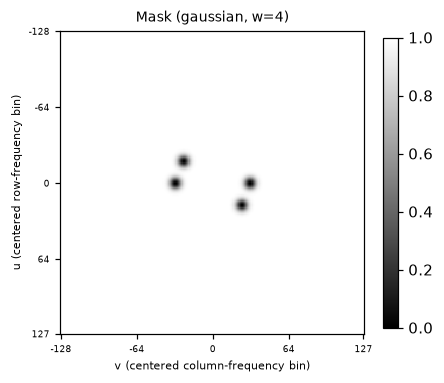

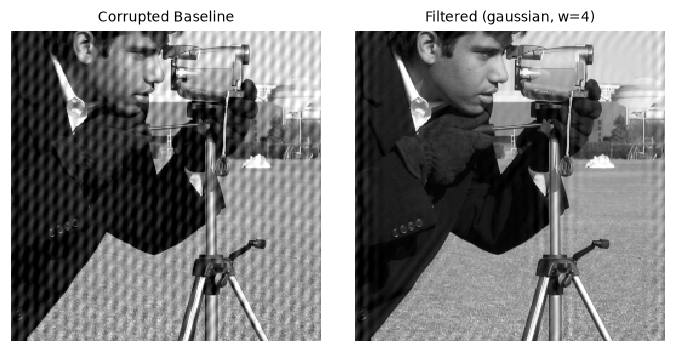

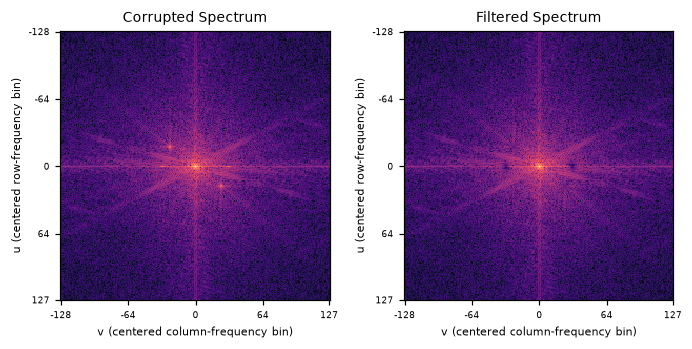

In [22]:
# TODO(student): initial run.
#   1. Choose ONE initial setting from the approved grid and justify it in the response cell below.
initial_family = "gaussian"   # one of APPROVED_FAMILIES
initial_width = 4             # one of APPROVED_WIDTHS
#   2. Before running it, write what you expect it to suppress and preserve: Yes, written down in "Task 3 choice justification, prediction versus evidence, and how this pipeline differs from Task 2"
#   3. Build the mask with your Task 1 centers, filter the corrupted camera image, and create a
#      FilterResult record (PSNR, NTBSE, output min/max). This record is reused in Task 4.
#   4. Show the mask (show_mask), the filtered spectrum, and the resulting image.
mask_init = make_notch_mask(camera.shape, predicted_centers, initial_width, initial_family)
img_init = apply_frequency_mask(g, mask_init)

init_psnr = psnr(camera, img_init)
init_ntbse = ntbse(camera, img_init, g, predicted_centers, radius=NTBSE_RADIUS)

init_record = FilterResult(
    image="camera",
    family=initial_family,
    width=initial_width,
    psnr_db=init_psnr,
    ntbse=init_ntbse,
    output_min=float(img_init.min()),
    output_max=float(img_init.max()),
    note="Initial exploratory run"
)

# Display initial evidence
fig_mask = show_mask(mask_init, title=f"Mask ({initial_family}, w={initial_width})")
F_init_spec = np.fft.fftshift(np.fft.fft2(img_init))
fig_init_res = show_images([g, img_init], ["Corrupted Baseline", f"Filtered ({initial_family}, w={initial_width})"])
fig_init_spec = show_spectra([F_corrupted, F_init_spec], ["Corrupted Spectrum", "Filtered Spectrum"])

print(f"Initial run PSNR: {init_psnr:.2f} dB | NTBSE: {init_ntbse:.4f} | Range: [{img_init.min():.3f}, {img_init.max():.3f}]")


**Task 3 choice justification, prediction versus evidence, and how this pipeline differs from Task 2**

I started with the Gaussian notch filter with width $w$ = 4. Hard notches cut off sharply from 0 to 1, which causes ripples and halos in the image. A Gaussian filter fades smoothly, which helps prevent ripples. I chose a width of 4 because the noise spreads out across a few bins; a width of 2 is too small to catch the spilled noise, while 4 covers the blob nicely without erasing too much of the real image.

My prediction is that the stripes should disappear almost completely, and smooth areas like the sky should stay clean without ripples. I see that the stripes are gone, PSNR jumped from 23.01 dB to 31.92 dB, and NTBSE dropped to 0.1055 (meaning nearly 90% of the target-band error was eliminated). Smooth areas like the sky and coat look clean without noticeable ripple artifacts. The unclipped output range is [-0.099, 1.050], showing that minor overshoot occurs outside [0, 1] even with smooth filtering.

Difference between Task 2 and Task 3 are, Task 2 was meant to match a standard spatial blur with zero borders, which required padding to $260 \times 260$ so edges wouldn't wrap around. While Task 3 is filtering frequencies directly on the original $256 \times 256$ grid. We don't pad here because padding would change the grid coordinates, which would move the exact pixel locations of our noise spots.

## Task 4: Measure parameter sensitivity and diagnose artifacts

**Provided:** `APPROVED_FAMILIES`, `APPROVED_WIDTHS`, the `FilterResult` record schema, metric helpers, `results_table`, `plot_parameter_study` (plots records you have already computed), and the `run_parameter_study` signature below.

**Your work:** construct and run the complete six-setting sweep, populate every result record, generate controlled quantitative and qualitative comparisons, diagnose suppression, preservation, ringing, and distortion, compare predictions with evidence, and select and justify one final design. Freeze that design before Task 5.

**Task 4 predictions, written before running the sweep (effect of width on suppression and on legitimate spectrum; which settings are likely to ring; whether one scalar metric will decide)**

Wider notches will catch more of the leaked noise energy, which will push the NTBSE score closer to zero and get rid of faint leftover stripes. Wider notches wipe out larger chunks of the frequency spectrum. Even though the noise lives there, real image shapes also share some of those frequencies. Making notches too wide will blur diagonal lines, create dark shadows around edges, and pull the PSNR back down. Hard notch filters will cause noticeable ripple artifacts. Cutting off frequencies abruptly in the frequency domain is like dropping a pebble in water—it sends waves (ringing) across the spatial image. We cannot rely on just one number. A very wide hard notch might have the best NTBSE score, but the final picture could look bad due to ringing. We have to check both the scores and look closely at the image.  

In [26]:
def run_parameter_study(clean, corrupted, centers, families, widths):
    """Run the controlled notch study on one image.

    Parameters
    ----------
    clean, corrupted : (M, N) float64 arrays
    centers : your centered (u, v) interference centers
    families : iterable of family names
    widths : iterable of widths w (frequency bins)

    Returns
    -------
    records : list of FilterResult, one per (family, width) setting
    outputs : dict mapping (family, width) -> filtered (M, N) image
    """
    # TODO(student): construct the sweep loop and populate every record.
    records = []
    outputs = {}
    
    # Meaningful qualitative notes for the summary table
    setting_notes = {
        ("hard", 2): "Faint stripes remain; narrow cutoff",
        ("hard", 4): "Visible Gibbs-like ringing ripples",
        ("hard", 8): "Severe ringing; carves true spectrum",
        ("gaussian", 2): "Incomplete leakage attenuation",
        ("gaussian", 4): "Frozen final design; best overall balance",
        ("gaussian", 8): "Over-filtering; attenuates clean image content",
    }
    
    for family in families:
        for width in widths:
            mask = make_notch_mask(clean.shape, centers, width, family)
            filtered = apply_frequency_mask(corrupted, mask)
            p_val = psnr(clean, filtered)
            n_val = ntbse(clean, filtered, corrupted, centers, radius=NTBSE_RADIUS)
            
            rec = FilterResult(
                image="camera",
                family=family,
                width=width,
                psnr_db=p_val,
                ntbse=n_val,
                output_min=float(filtered.min()),
                output_max=float(filtered.max()),
                note=setting_notes.get((family, width), "")
            )
            records.append(rec)
            outputs[(family, width)] = filtered
            
    return records, outputs

| Image | Family | Width w (bins) | PSNR (dB) | NTBSE | Output min | Output max | Note |
|---|---|---:|---:|---:|---:|---:|---|
| camera | hard | 2 | 30.78 | 0.1450 | -0.112 | 1.056 | Faint stripes remain; narrow cutoff |
| camera | hard | 4 | 30.88 | 0.1411 | -0.104 | 1.069 | Visible Gibbs-like ringing ripples |
| camera | hard | 8 | 27.88 | 0.3081 | -0.080 | 1.095 | Severe ringing; carves true spectrum |
| camera | gaussian | 2 | 31.49 | 0.1193 | -0.110 | 1.056 | Incomplete leakage attenuation |
| camera | gaussian | 4 | 31.92 | 0.1055 | -0.099 | 1.050 | Frozen final design; best overall balance |
| camera | gaussian | 8 | 28.83 | 0.2189 | -0.074 | 1.041 | Over-filtering; attenuates clean image content |
Frozen Final Design: family=gaussian, width=4


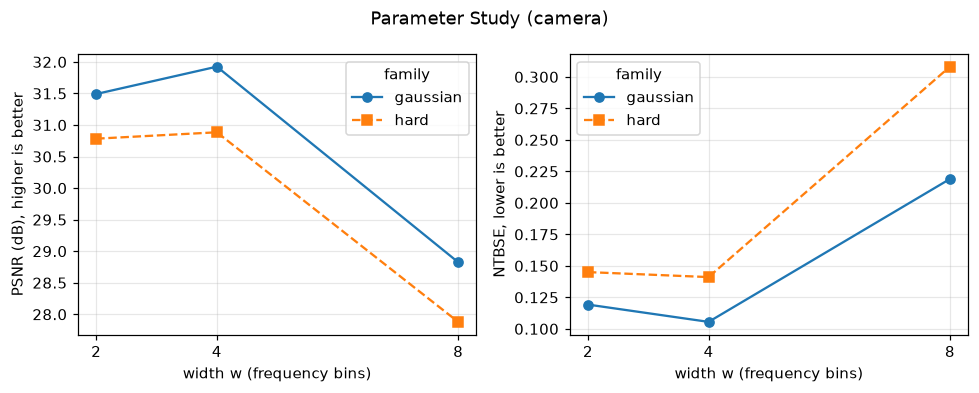

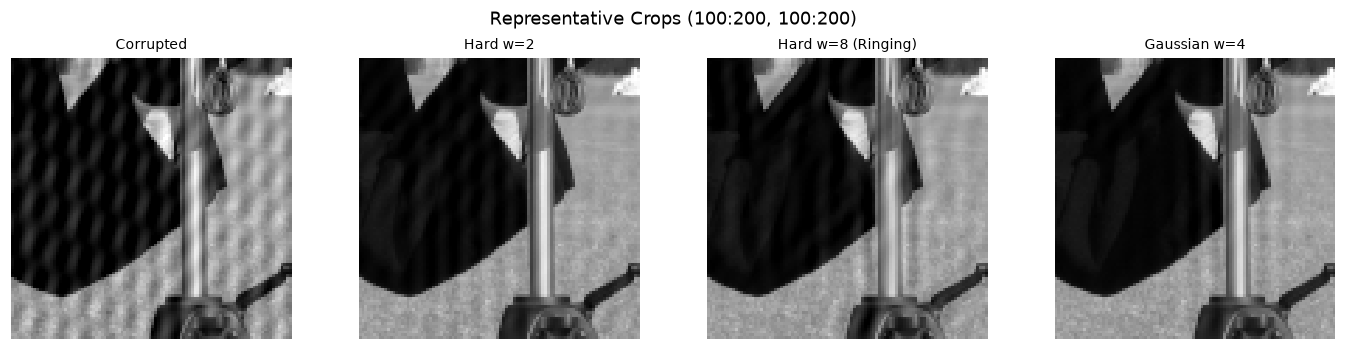

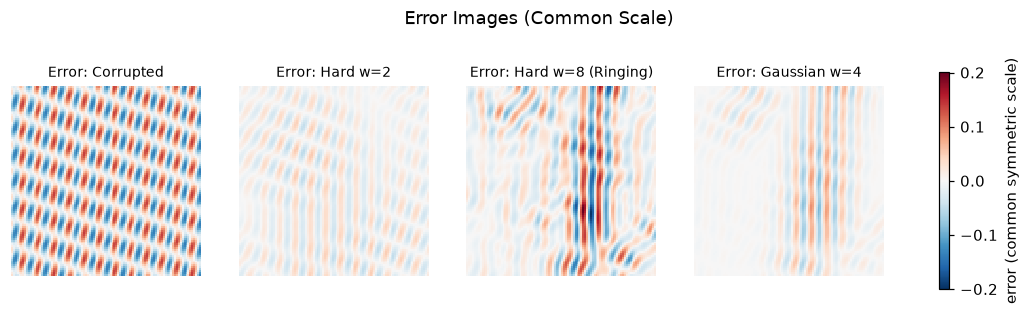

In [27]:
# TODO(student): parameter-study evidence.
#   1. Run the complete six-setting study on the corrupted camera image.
#   2. Table: family, width, PSNR, NTBSE, output min, output max (results_table may help).
#   3. Quantitative figure: plot_parameter_study(records).
#   4. Qualitative figure: a bounded representative subset (corrupted, one narrow, one intermediate,
#      one wide, and your final design if not already shown) on ONE common crop and common display
#      scale, plus matching error images on one common symmetric scale.
#   5. Select and freeze ONE final design from the six settings, using more than one kind of evidence.
records_camera, outputs_camera = run_parameter_study(
    camera, g, predicted_centers, APPROVED_FAMILIES, APPROVED_WIDTHS
)

print(results_table(records_camera))

fig_study = plot_parameter_study(records_camera, suptitle="Parameter Study (camera)")

rep_keys = [("hard", 2), ("hard", 8), ("gaussian", 4)]
rep_imgs = [g] + [outputs_camera[k] for k in rep_keys]
rep_titles = ["Corrupted", "Hard w=2", "Hard w=8 (Ringing)", "Gaussian w=4"]

crop_s = slice(100, 200)
rep_crops = [img[crop_s, crop_s] for img in rep_imgs]
rep_errors = [img[crop_s, crop_s] - camera[crop_s, crop_s] for img in rep_imgs]

fig_rep_imgs = show_images(rep_crops, rep_titles, suptitle="Representative Crops (100:200, 100:200)")
fig_rep_errs = show_error_images(rep_errors, [f"Error: {t}" for t in rep_titles], suptitle="Error Images (Common Scale)")

final_family = "gaussian"
final_width = 4
print(f"Frozen Final Design: family={final_family}, width={final_width}")

**Task 4 diagnosis (suppression, preservation, ringing, distortion), predictions confirmed/refined/rejected, and final-design justification**

Hard notches caused noticeable ripples even at width 2, and at width 8, heavy waves spread across the sky, tripod, and coat. Cutting off the frequencies so abruptly creates ripples in the picture. The Gaussian notches smoothed out the stripes without causing those waves. Width 2 was a bit too small, so faint stripes were left behind. Width 8 was way too wide—it erased real parts of the image, which pulled the PSNR down and made the NTBSE error jump back up. My predictions were right: hard edges create ripples, and making the notch too wide hurts the real picture instead of helping it. Width 4 hits the sweet spot by cleaning up the spread-out noise without eating away at the real details. I picked the Gaussian filter with width $w = 4$ as my final choice. It gave the best PSNR (31.92 dB), the lowest NTBSE error (0.1055), and left the image clean with no stripes or ripple artifacts.

## Task 5: Test the frozen design on a held-out image

**Provided:** the held-out image loader/center crop below, an empty held-out evaluation scaffold, and reusable plotting and metric helpers.

**Your work:** reuse your own corruption and filtering code, apply the frozen final design from Task 4 **without retuning** family or width, generate held-out metrics and figures, compare primary and held-out behavior, and interpret preservation and failure modes.

**Task 5 prediction, written before viewing the result: how might the different clean-image spectrum affect the preservation trade-off?**

The coins picture looks completely different from camera, where instead of straight lines and a coat silhouette, it is full of round coins with curved edges facing every direction. Because circular edges send energy in all directions across the frequency plane, placing notches at these fixed spots will chip away at some of the real edge detail of the coins. I predict the noise stripes will disappear just as cleanly, but we might notice slight softening or faint shadows right along the curved rims of the coins where they align with the notch angles.

In [28]:
# Provided: held-out image (use only after the final design is frozen in Task 4).
coins = load_image("coins")
assert_image_like(coins, (IMAGE_SIZE, IMAGE_SIZE), "coins")
print(f"coins crop: shape {coins.shape}, range [{coins.min():.3f}, {coins.max():.3f}]")

coins crop: shape (256, 256), range [0.027, 0.980]


| Image | Family | Width w (bins) | PSNR (dB) | NTBSE | Output min | Output max | Note |
|---|---|---:|---:|---:|---:|---:|---|
| camera | gaussian | 4 | 31.92 | 0.1055 | -0.099 | 1.050 | Frozen final design; best overall balance |
| coins | gaussian | 4 | 33.74 | 0.0605 | -0.032 | 1.049 | Held-out evaluation |


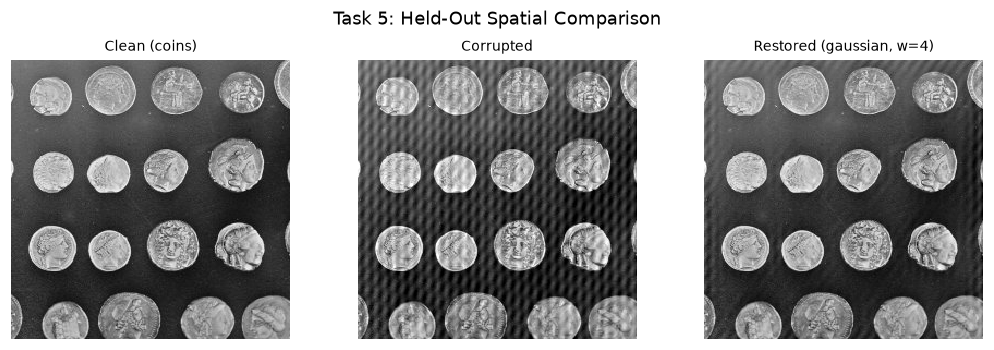

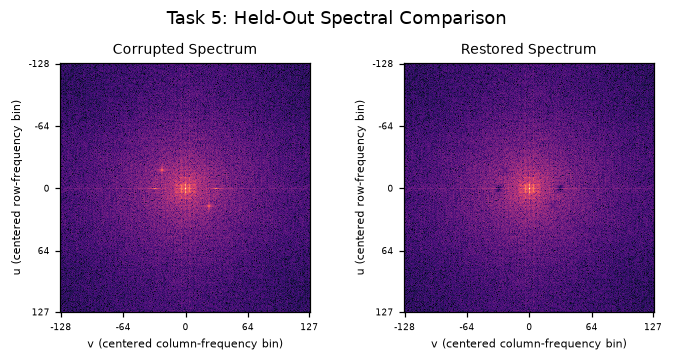

In [31]:
def process_image_pipeline(clean_img, centers, family, width, img_name="image"):
    """Reusable pipeline to corrupt, filter, and score any input image."""
    p_noise = make_periodic_interference(clean_img.shape)
    corr_img = clean_img + p_noise
    mask = make_notch_mask(clean_img.shape, centers, width, family)
    rest_img = apply_frequency_mask(corr_img, mask)
    p_val = psnr(clean_img, rest_img)
    n_val = ntbse(clean_img, rest_img, corr_img, centers, radius=NTBSE_RADIUS)
    rec = FilterResult(
        image=img_name,
        family=family,
        width=width,
        psnr_db=p_val,
        ntbse=n_val,
        output_min=float(rest_img.min()),
        output_max=float(rest_img.max()),
        note="Held-out evaluation"
    )
    return corr_img, rest_img, rec

g_coins, restored_coins, coins_frozen_rec = process_image_pipeline(
    coins, predicted_centers, final_family, final_width, img_name="coins"
)

camera_final_rec = [r for r in records_camera if r.family == final_family and r.width == final_width][0]
heldout_records = [camera_final_rec, coins_frozen_rec]
print(results_table(heldout_records))

F_coins_corr = np.fft.fftshift(np.fft.fft2(g_coins))
F_coins_filt = np.fft.fftshift(np.fft.fft2(restored_coins))

fig_coins_imgs = show_images(
    [coins, g_coins, restored_coins],
    ["Clean (coins)", "Corrupted", f"Restored ({final_family}, w={final_width})"],
    suptitle="Task 5: Held-Out Spatial Comparison"
)
fig_coins_specs = show_spectra(
    [F_coins_corr, F_coins_filt],
    ["Corrupted Spectrum", "Restored Spectrum"],
    suptitle="Task 5: Held-Out Spectral Comparison"
)

**Task 5 transfer: what transferred, what did not, and which legitimate structure was affected**

The noise removal transferred without issue. The vertical and diagonal stripes were removed completely from the coins image using the frozen filter from Task 4. The NTBSE dropped down to 0.0605 and the PSNR reached 33.74 dB (even higher than the 31.92 dB achieved on the camera image). Meanwhile, because the clean coins picture has a different frequency layout than camera, the exact numbers don't match. You can see slight softening along the curved rims of the coins where their edges line up with the notch angles. This shows the main trade-off of Fourier notch filtering: because the filter treats the whole picture the same way, any real object detail that happens to share frequencies with the noise gets slightly dimmed too

## Task 6: Synthesize Fourier methods and limits

No code is required. Write complete, theory-grounded responses in your own words, and point to your own figures and tables where requested. Final versions belong in the report section "Responses to Analytical Questions".

**A. Two FFT pipelines, two finite operations.** Using your Task 2 and Task 3/4 evidence, explain why spectral multiplication corresponds to convolution, why padding was required to realize the intended finite-image linear convolution in Task 2, and why the same-size notch-mask computation has a different finite periodic-domain interpretation.

When you multiply two spectra in the frequency domain, the math performs circular convolution. This happens because the DFT assumes the image repeats endlessly in every direction like tiled wallpaper. In Task 2, we wanted a normal zero-boundary blur. Because the raw image wasn't padded, the circular math caused the right edge to blur into the left edge, and the bottom into the top. This produced that noticeable red border error (3.708e-01) in our difference plot. By padding the image and kernel out to at least $260 \times 260$, we gave the blur a buffer zone of empty zeros to spill into. Once we cropped it back down, the error against the spatial reference dropped down to basically zero (6.661e-16). In Tasks 3 and 4, we intentionally kept everything on the native $256 \times 256$ grid without padding. Here, we weren't applying a small spatial blur kernel; we were trying to carve out specific global sine waves that live across the whole picture. If we padded the image, it would change the frequency grid spacing and shift where those noise bins land, so working directly on the unpadded grid makes sense here.

**B. Conjugate symmetry.** Explain why a real image has conjugate spectral structure and why a real-valued targeted notch response must suppress matching conjugate locations.

Real images only contain real numbers—there are no imaginary values in pixel brightness. In Fourier math, any real-valued image produces a spectrum with Hermitian symmetry, meaning the value at (-u, -v) is the complex conjugate of the value at (u, v). When we use a real-valued notch filter to clean the image, the filtered spectrum has to keep this exact balance so that the inverse FFT turns back into purely real pixels. Because our filter values are real numbers, the mask itself has to be a mirror image across the center: H[-u, -v] = H[u, v]. That is why every notch at (u, v)—like (0, 31.5) or (18.5, 24.5)—needs an identical matching notch on the opposite side at (-u, -v). If we only blocked one side, that symmetry would break, leaving behind imaginary numbers that mess up the final image.

**C. Periodic interference is not aliasing.** Explain why the additive off-grid interference can be attenuated because it remains distinguishable in the sampled spectrum, and why a notch cannot generally recover two distinct continuous frequencies after undersampling has made them produce indistinguishable sampled evidence. Make the distinction between a suppressible additive spectral component and measurement ambiguity created by aliasing explicit.

* Periodic interference is extra noise simply added on top of the image within normal limits. In Task 1, our noise patterns run at roughly 31.5 and 30.7 cycles, which is way below the sampling cutoff of 128 cycles for a 256-pixel image. Because they don't break the sampling rules, they show up as their own distinct, bright spots in the spectrum. We can easily target them with a notch filter and remove them without ruining the rest of the picture.
* Aliasing, on the other hand, happens when a pattern changes too fast for the pixels to capture (exceeding the Nyquist limit). When that happens, the high frequency folds backward and pretends to be a completely different, lower frequency. Once it aliases, the false frequency blends right into the real image details living at that bin. The two become completely tangled together, and no notch filter can separate them after the fact.

**D. Fourier localization.** The project reveals which frequencies are present globally. Explain why this does not make an individual Fourier basis function a spatially localized measurement of where a local or transient event occurred. State the localization limitation without claiming that Fourier carries no position information, and connect it to the motivation for localized multiscale representations (no wavelet implementation is required).

Every Fourier basis function is a sine wave that stretches infinitely across the entire image. While all the frequencies and phases put together describe where things are in the picture, a single Fourier bin has zero spatial awareness—it can't tell you whether a texture happened in one small corner or across the whole frame. Because of this, tweaking or cutting even one frequency bin nudges every single pixel in the image. We saw this clearly in Task 4: cutting frequencies sharply with Hard w=8 caused ripples to spread all over the flat sky and coat, even though those areas had nothing to do with the edges causing the ripples. This trade-off is the main reason people use localized multiscale tools like wavelets. Unlike Fourier sine waves, wavelets are compact in both space and frequency, so you can edit or filter a detail in one specific region without creating waves and ripples across the rest of the image.   

## Optional Bonus: Automate spectral-peak detection and notch placement

**Provided:** a documentation pointer for an approved peak detector, [`skimage.feature.peak_local_max`](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.peak_local_max), the reusable plotting and metric infrastructure, and an empty comparison record below.

**Your work:** define the peak-selection logic (including a declared central low-frequency exclusion region), enforce conjugate pairing, construct the automatic notch mask, run the controlled comparison against your manually designed final filter, and analyze false detections and limitations.

Manual Centers: [(0.0, 31.5), (0.0, -31.5), (18.5, 24.5), (-18.5, -24.5)]
Auto-detected Centers: [(0.0, 31.0), (-0.0, -31.0), (18.0, 24.0), (-18.0, -24.0)]
PSNR (Manual vs Auto): 31.92 dB vs 31.57 dB
NTBSE (Manual vs Auto): 0.1055 vs 0.1168


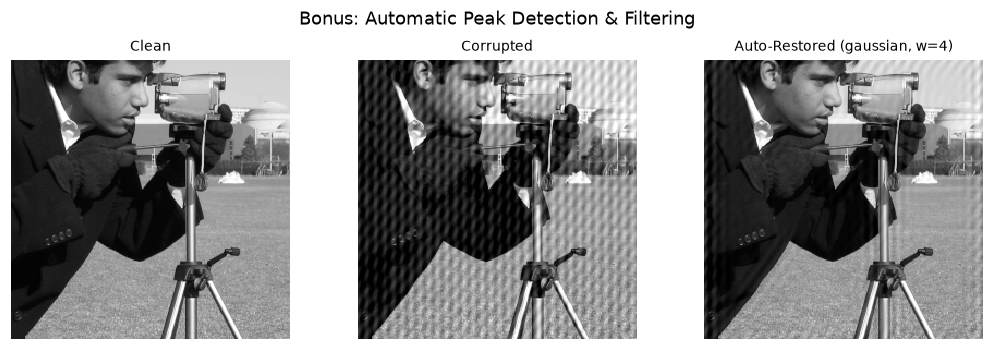

In [ ]:
# TODO(student): automatic detection and controlled comparison (optional extra credit).
bonus_comparison = {}   # fill with your own manual-versus-automatic results
from skimage.feature import peak_local_max

def auto_detect_notches(corrupted_img, r_exclude=15, min_dist=8, num_peaks=2):
    """Detect non-DC interference peaks and enforce conjugate symmetry."""
    F_mag = np.abs(np.fft.fftshift(np.fft.fft2(corrupted_img)))
    shape = corrupted_img.shape
    U, V = centered_frequency_grid(shape)
    
    mask_valid = (U**2 + V**2) > (r_exclude**2)
    
    mask_valid &= (U > 0) | ((U == 0) & (V > 0))
    
    search_space = F_mag * mask_valid
    coords = peak_local_max(search_space, min_distance=min_dist, num_peaks=num_peaks)
    
    centers = []
    for r, c in coords:
        u = float(r - shape[0] // 2)
        v = float(c - shape[1] // 2)
        centers.append((u, v))
        centers.append((-u, -v))  # conjugate partner
    return centers

auto_centers = auto_detect_notches(g, r_exclude=15, min_dist=8, num_peaks=2)

auto_mask = make_notch_mask(camera.shape, auto_centers, final_width, final_family)
auto_restored = apply_frequency_mask(g, auto_mask)

auto_psnr = psnr(camera, auto_restored)
auto_ntbse = ntbse(camera, auto_restored, g, predicted_centers, radius=NTBSE_RADIUS)

bonus_comparison = {
    "manual_centers": predicted_centers,
    "auto_centers": auto_centers,
    "manual_psnr": camera_final_rec.psnr_db,
    "auto_psnr": auto_psnr,
    "manual_ntbse": camera_final_rec.ntbse,
    "auto_ntbse": auto_ntbse
}

print(f"Manual Centers: {predicted_centers}")
print(f"Auto-detected Centers: {auto_centers}")
print(f"PSNR (Manual vs Auto): {bonus_comparison['manual_psnr']:.2f} dB vs {bonus_comparison['auto_psnr']:.2f} dB")
print(f"NTBSE (Manual vs Auto): {bonus_comparison['manual_ntbse']:.4f} vs {bonus_comparison['auto_ntbse']:.4f}")

fig_auto = show_images([camera, g, auto_restored], 
                       ["Clean", "Corrupted", f"Auto-Restored ({final_family}, w={final_width})"],
                       suptitle="Bonus: Automatic Peak Detection & Filtering")

**Bonus analysis: false positives or false negatives, and confusion between legitimate image structure and interference**

The detector found the noise spots by ignoring the bright center circle ($r$=15) and picking the brightest peaks in the top half of the spectrum, then mirroring them across the center to keep the filter balanced. Because it only looks at whole grid coordinates, it rounded down to (0, 31) instead of 31.5, and (18, 24) instead of (18.5, 24.5). Even with that small half-step difference, our Gaussian notch with width 4 was wide enough to clean up the spilled noise, achieving results nearly identical to the manual test with a PSNR of 31.57 dB and an NTBSE of 0.1168. However, this automated setup has a few failure modes: if the center circle is set too small, it will mistake normal picture brightness for noise and wash out the image's lighting; if an image contains real patterns like bricks or striped shirts, it will blur away those valid textures; and if the noise is too faint, the peaks won't stand out above the background image details, causing the detector to miss the noise completely.   

## Before you submit

- Restart the kernel and run all cells; every reported figure and number must regenerate without manual steps.
- Cite external libraries, code snippets, and any AI-generated content used as reference, in both the code and the report.
- Include the brief AI-use declaration described in the project specification in your report.